# Abdul Mannan Ibrahim 
# 23-NTU-CS-1003
# Class Lab 7

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [3]:
from sklearn.datasets import fetch_openml

elec_data = fetch_openml(name='electricity', version=1)
elec_df = elec_data.frame

print("Data shape:", elec_data.data.shape)
print("Feature names:", elec_data.feature_names)
print("Target names:", elec_data.target_names)

Data shape: (45312, 8)
Feature names: ['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer']
Target names: ['class']


In [6]:

from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(elec_df, test_size=0.25, random_state=20)
print(len(train_data), len(test_data))

33984 11328


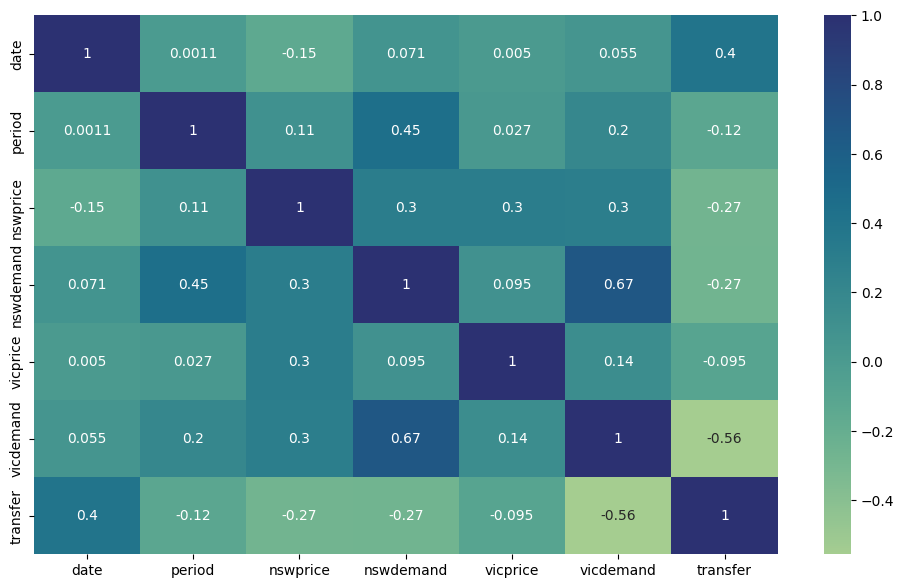

In [7]:
corr = train_data.corr(numeric_only=True)

plt.figure(figsize=(12, 7))
sns.heatmap(corr, annot=True, cmap='crest')
plt.show()

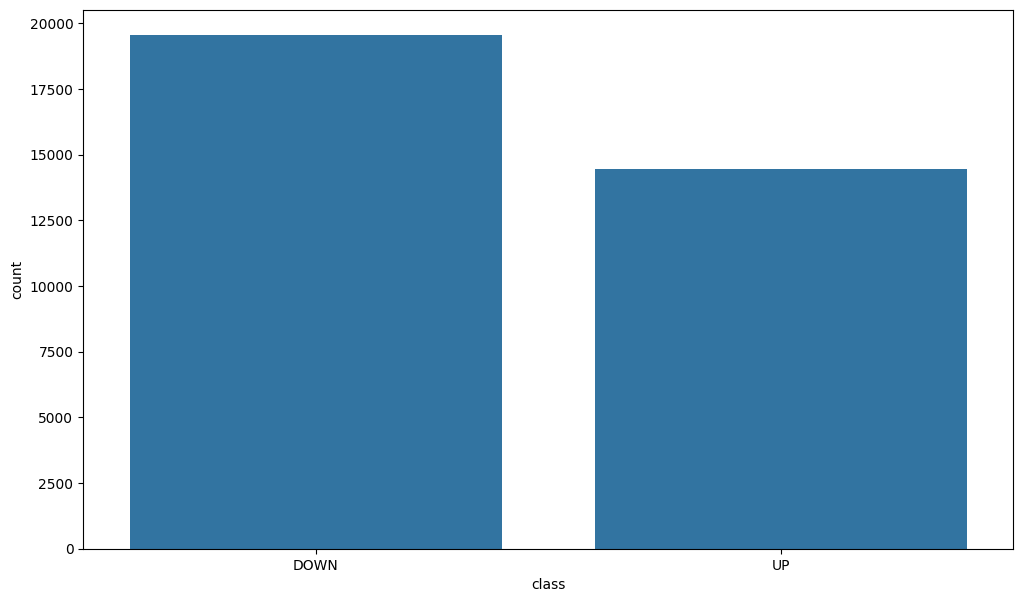

In [8]:
plt.figure(figsize=(12, 7))
sns.countplot(data=train_data, x='class')
plt.show()

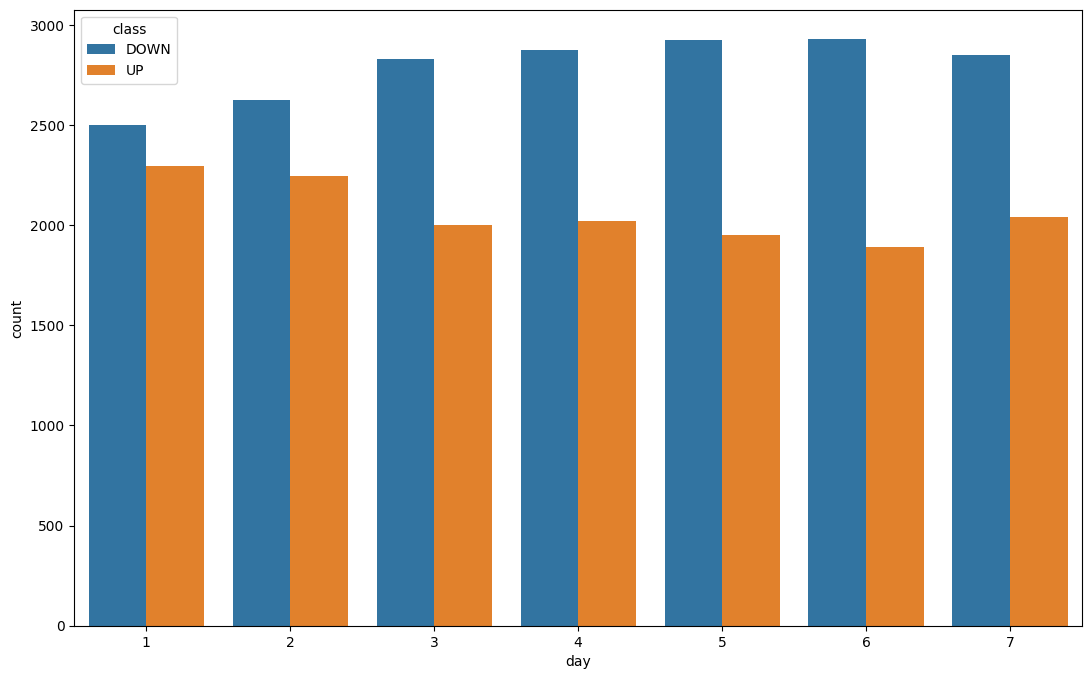

In [9]:
plt.figure(figsize=(13, 8))
sns.countplot(data=train_data, x='day', hue='class')
plt.show()

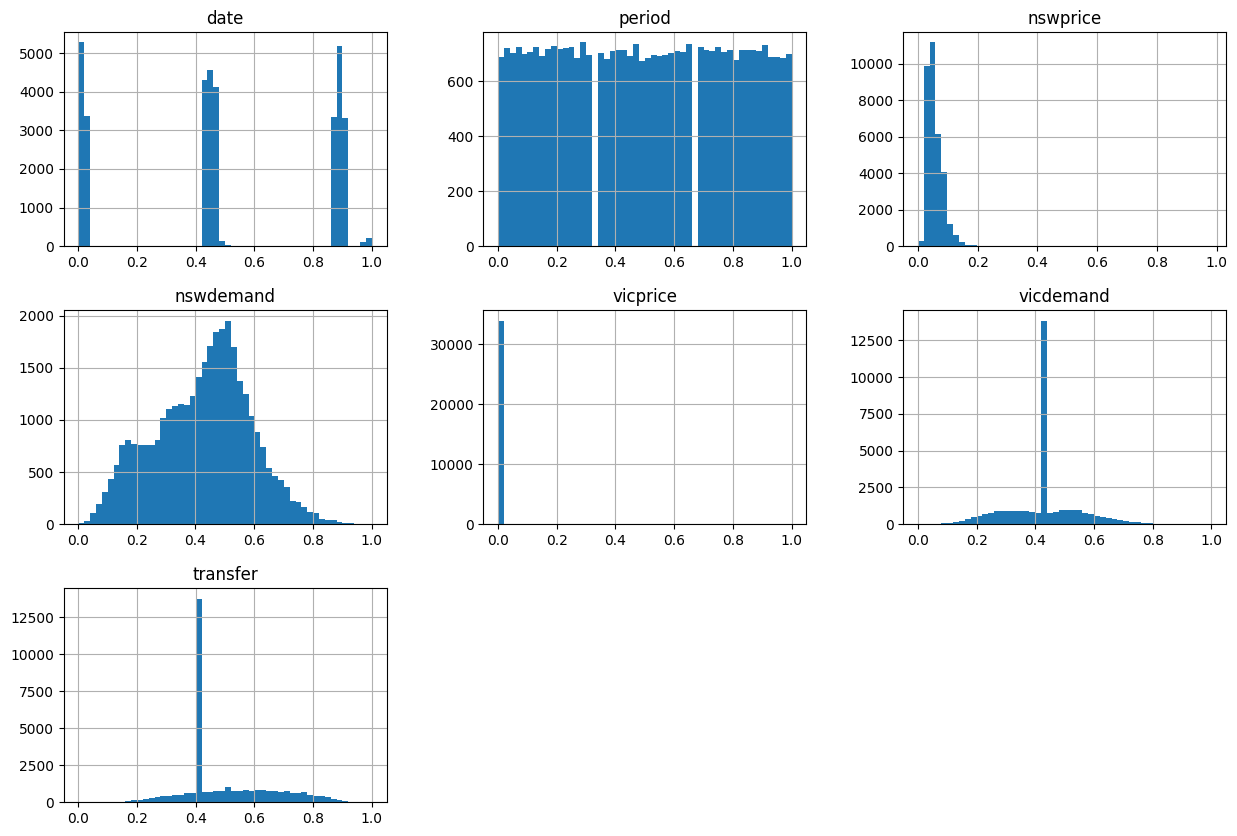

In [10]:
train_data.hist(bins=50, figsize=(15, 10))
plt.show()

In [11]:
from sklearn.preprocessing import LabelEncoder

X_train = train_data.drop('class', axis=1)
y_train = train_data['class']

label_enc = LabelEncoder()
y_train_prepared = label_enc.fit_transform(y_train)

print(label_enc.classes_)

['DOWN' 'UP']


In [12]:
from sklearn.metrics import accuracy_score

def accuracy(model, data, labels):
    predictions = model.predict(data)
    acc = accuracy_score(labels, predictions)

    return acc

In [13]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_classifier = BaggingClassifier(
    DecisionTreeClassifier(class_weight='balanced'),
    max_samples=0.5, max_features=0.5, bootstrap=False
)

bag_classifier.fit(X_train, y_train_prepared)
print(accuracy(bag_classifier, X_train, y_train_prepared))

0.981962099811676


In [14]:
from sklearn.ensemble import GradientBoostingClassifier

grad_boost_clf = GradientBoostingClassifier(
    n_estimators=500,
    learning_rate=0.8,
    random_state=42,
    max_depth=2
)

grad_boost_clf.fit(X_train, y_train_prepared)
print(accuracy(grad_boost_clf, X_train, y_train_prepared))

0.9269362052730696


In [15]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

adaboost_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, class_weight='balanced'),
    n_estimators=300,
    learning_rate=0.5
)

adaboost_clf.fit(X_train, y_train_prepared)
print(accuracy(adaboost_clf, X_train, y_train_prepared))

0.7966395951035782


In [ ]:
# pip install xgboost
%pip install xgboost
import xgboost as xgb

xgb_clf = xgb.XGBClassifier()
xgb_clf.fit(X_train, y_train_prepared)

In [ ]:
X_test = test_data.drop('class', axis=1)
y_test = test_data['class']

y_test_prepared = label_enc.transform(y_test)

print(accuracy(grad_boost_clf, X_test, y_test_prepared))
print(accuracy(bag_classifier, X_test, y_test_prepared))